<a href="https://colab.research.google.com/github/maobapei/Nasa-asteroid-classification/blob/main/ADY201m_Group2_AI2101.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo"  />
</center>

# ADY201m - AI, DATA SCIENCE WITH PYTHON & SQL

   

---

# 1. Data Collection
---

In [ ]:
import os
import pandas as pd
import requests
from google.colab import files, userdata

FILE_NAME = 'thien_thach_raw.csv'

if os.path.exists(FILE_NAME):
    df = pd.read_csv(FILE_NAME)
else:
    API_KEY = userdata.get('NASA_API_KEY')
    dong_trong_bang = []

    for trang in range(400):
        url = f'https://api.nasa.gov/neo/rest/v1/neo/browse?page={trang}&api_key={API_KEY}'
        data = requests.get(url).json()

        for thien_thach in data.get('near_earth_objects', []):
            quy_dao = thien_thach.get('orbital_data', {})
            dong_trong_bang.append({
                'Mã định danh': thien_thach.get('neo_reference_id'),
                'Tên thiên thạch': thien_thach.get('name'),
                'Độ bất định quỹ đạo': quy_dao.get('orbit_uncertainty'),
                'Cấp sao tuyệt đối': thien_thach.get('absolute_magnitude_h'),
                'Đường kính vật thể': thien_thach.get('estimated_diameter', {}).get('kilometers', {}).get('estimated_diameter_max'),
                'Khoảng cách giao cắt quỹ đạo tối thiểu': quy_dao.get('minimum_orbit_intersection'),
                'Độ lệch tâm': quy_dao.get('eccentricity'),
                'Bán trục lớn': quy_dao.get('semi_major_axis'),
                'Độ nghiêng quỹ đạo': quy_dao.get('inclination'),
                'Chu kỳ quỹ đạo': quy_dao.get('orbital_period'),
                'Nguy hiểm': int(thien_thach.get('is_potentially_hazardous_asteroid', 0)),
            })

    df = pd.DataFrame(dong_trong_bang)
    df.to_csv(FILE_NAME, index=False)
    files.download(FILE_NAME)

## 1.1 Read data
---

In [ ]:
df_raw = pd.read_csv(FILE_NAME)
print(f"Dataset shape: {df_raw.shape}")
display(df_raw.head())

Dataset shape: (8000, 11)


,Mã định danh,Tên thiên thạch,Độ bất định quỹ đạo,Cấp sao tuyệt đối,Đường kính vật thể,Khoảng cách giao cắt quỹ đạo tối thiểu,Độ lệch tâm,Bán trục lớn,Độ nghiêng quỹ đạo,Chu kỳ quỹ đạo,Nguy hiểm
0,2001620,1620 Geographos (1951 RA),0,15.27,5.248558,0.029531,0.335518,1.245804,13.336755,507.893683,1
1,2001863,1863 Antinous (1948 EA),0,15.32,5.129086,0.188050,0.606232,2.259384,18.383883,1240.461761,0
2,2001915,1915 Quetzalcoatl (1953 EA),0,18.38,1.253257,0.110002,0.570256,2.545293,20.399683,1483.218034,0
3,2001917,1917 Cuyo (1968 AA),0,14.38,7.907514,0.071792,0.505427,2.149232,23.956068,1150.861948,0
4,2002063,2063 Bacchus (1977 HB),0,17.21,2.148028,0.066978,0.349231,1.077501,9.432223,408.530807,0


## 1.2 Read the data information
---

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 11 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Mã định danh                            8000 non-null   int64  
 1   Tên thiên thạch                         8000 non-null   object 
 2   Độ bất định quỹ đạo                     8000 non-null   int64  
 3   Cấp sao tuyệt đối                       7993 non-null   float64
 4   Đường kính vật thể                      7993 non-null   float64
 5   Khoảng cách giao cắt quỹ đạo tối thiểu  8000 non-null   float64
 6   Độ lệch tâm                             8000 non-null   float64
 7   Bán trục lớn                            8000 non-null   float64
 8   Độ nghiêng quỹ đạo                      8000 non-null   float64
 9   Chu kỳ quỹ đạo                          8000 non-null   float64
 10  Nguy hiểm                               8000 non-null   int6

### 1.2.1 Phân tích dòng trùng

In [ ]:
# 1. Đếm số lượng dòng bị trùng Mã định danh
print("Số dòng trùng ID:", df_raw['Mã định danh'].duplicated().sum())
# 2. Đếm số lượng dòng trùng khớp toàn bộ thuộc tính đặc trưng nhưng khác ID
print("Số dòng trùng thuộc tính (khác ID):", df_raw.duplicated(subset=df_raw.columns.difference(['Mã định danh'])).sum())

Số dòng trùng ID: 0
Số dòng trùng thuộc tính (khác ID): 0


### 1.2.2 Phân tích dòng thiếu

In [ ]:
# Tạo mặt nạ kiểm tra vị trí khuyết dữ liệu
thieu_cap_sao = df_raw['Cấp sao tuyệt đối'].isna()
thieu_duong_kinh = df_raw['Đường kính vật thể'].isna()

# 1. Thiếu Cấp sao tuyệt đối nhưng Có Đường kính vật thể
thieu_cs_co_dk = (thieu_cap_sao & ~thieu_duong_kinh).sum()

# 2. Có Cấp sao tuyệt đối nhưng Thiếu Đường kính vật thể
co_cs_thieu_dk = (~thieu_cap_sao & thieu_duong_kinh).sum()

# 3. Thiếu cả hai cột
thieu_ca_hai = (thieu_cap_sao & thieu_duong_kinh).sum()

# In kết quả
print("Thiếu Cấp sao & Có Đường kính:", thieu_cs_co_dk)
print("Có Cấp sao & Thiếu Đường kính:", co_cs_thieu_dk)
print("Thiếu cả hai:", thieu_ca_hai)

Thiếu Cấp sao & Có Đường kính: 0
Có Cấp sao & Thiếu Đường kính: 0
Thiếu cả hai: 7


# 2. Data Cleaning
---

In [ ]:
# 1. Loại bỏ 2 cột định danh không chứa thuộc tính vật lý
df_clean = df_raw.drop(columns=['Mã định danh', 'Tên thiên thạch'])

# 2. Loại bỏ 7 dòng bị khuyết dữ liệu
df_clean = df_clean.dropna()

# 3. Xuất tập dữ liệu sạch ra file CSV (index=False để không lưu cột chỉ số dòng thừa)
df_clean.to_csv('thien_thach_clean.csv', index=False)

### 2.1 Before & After

In [ ]:
print(f"Kích thước gốc (df_raw)  : {df_raw.shape}")
print(f"Kích thước sạch (df_clean): {df_clean.shape}")

Kích thước gốc (df_raw)  : (8000, 11)
Kích thước sạch (df_clean): (7993, 9)


# 3. EDA

---

## Biểu đồ 1: Box plot
#### Mục tiêu: Quan sát phân bố dữ liệu và sự xuất hiện của giá trị ngoại lệ (outliers) trên các đặc trưng vật lý, từ đó làm căn cứ lựa chọn phướng án scale (min-max, standard, robust) và thuật toán huấn luyện phù hợp

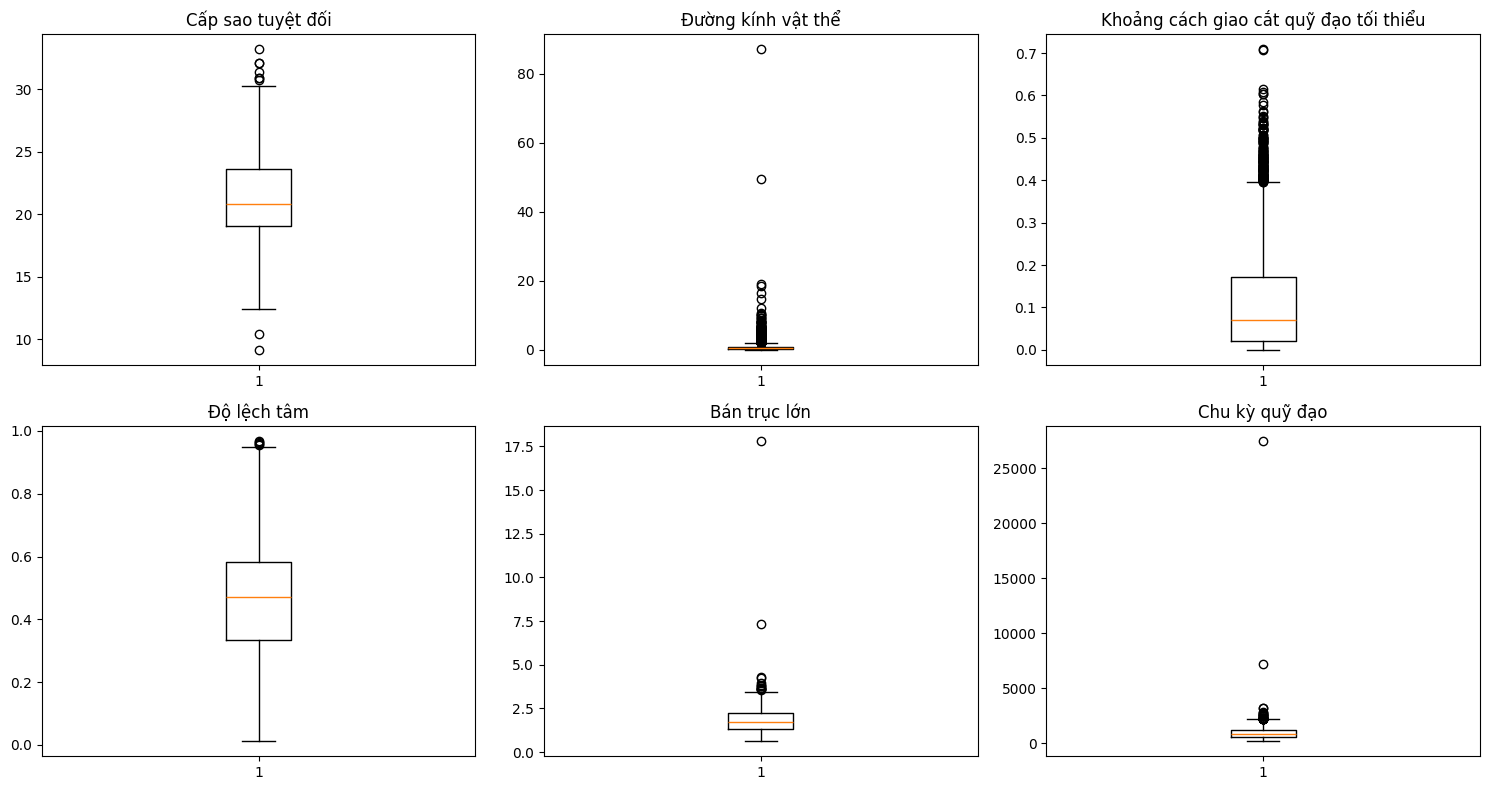

In [ ]:
import matplotlib.pyplot as plt

cot_noi_bat = [
    'Cấp sao tuyệt đối',
    'Đường kính vật thể',
    'Khoảng cách giao cắt quỹ đạo tối thiểu',
    'Độ lệch tâm',
    'Bán trục lớn',
    'Chu kỳ quỹ đạo'
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(cot_noi_bat):
    axes[i].boxplot(df_clean[col].dropna())
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

### Kiểm tra số lượng chính xác outlier

In [ ]:
# Đếm và tính tỷ lệ % outlier cho từng cột
for col in cot_noi_bat:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    # Số dòng nằm ngoài ranh giới (Q1 - 1.5*IQR) và (Q3 + 1.5*IQR)
    so_outliers = ((df_clean[col] < Q1 - 1.5 * IQR) | (df_clean[col] > Q3 + 1.5 * IQR)).sum()
    ty_le = (so_outliers / len(df_clean)) * 100

    print(f"{col}: {ty_le:.2f}% ({so_outliers}/{len(df_clean)} dòng)")

Cấp sao tuyệt đối: 0.11% (9/7993 dòng)
Đường kính vật thể: 6.91% (552/7993 dòng)
Khoảng cách giao cắt quỹ đạo tối thiểu: 2.08% (166/7993 dòng)
Độ lệch tâm: 0.06% (5/7993 dòng)
Bán trục lớn: 0.18% (14/7993 dòng)
Chu kỳ quỹ đạo: 0.40% (32/7993 dòng)


### Nhận xét & Kết luận từ Biểu đồ Boxplot

* **Hiện trạng phân bố:** Các đặc trưng vật lý và quỹ đạo đều bị **lệch phải nặng** (Right-skewed) và xuất hiện **nhiều giá trị ngoại lệ** (outliers) tập trung ở phía trên (đặc biệt là *Đường kính vật thể* và *Khoảng cách giao cắt quỹ đạo tối thiểu*).
* **Bản chất dữ liệu:** Đây là các thông số vật lý thực tế của thiên thạch do NASA đo đạc, không phải lỗi nhập liệu hay nhiễu dữ liệu.
* **Quyết định xử lý:**
  1. **Giữ nguyên $100\%$ Outliers**, sử dụng Robust Scaler chống outlier tốt.
  2. **Định hướng mô hình:** Ưu tiên sử dụng các thuật toán dạng **Cây quyết định (LightGBM, XGBoost)** vì khả năng trơ với ngoại lệ và không phụ thuộc vào dạng phân bố của dữ liệu, giúp bỏ qua bước chuẩn hóa scaling phức tạp.

## Biểu đồ 2: Count plot
#### Mục tiêu: Thống kê tỷ lệ thiên thạch thuộc từng lớp nhãn, để kiểm tra xem dữ liệu có bị mất cân bằng nhãn (Class Imbalance) hay không, từ đó lựa chọn chỉ số đánh giá phù hợp (F1-Score, PR-AUC, AUC-ROC or Accuracy)


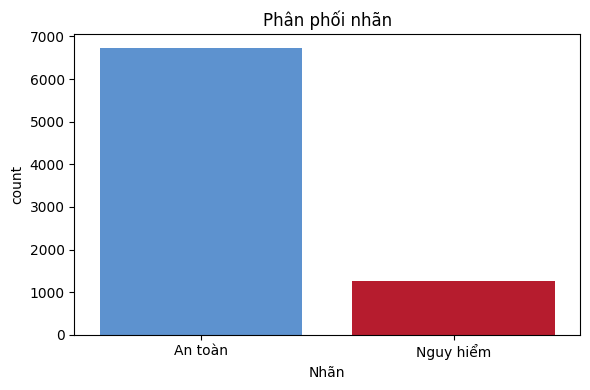

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_ve = df_clean.copy()
df_ve['Nhãn'] = df_ve['Nguy hiểm'].map({0: 'An toàn', 1: 'Nguy hiểm'})
mau = {'An toàn': '#4A90E2', 'Nguy hiểm': '#D0021B'}

plt.figure(figsize=(6, 4))
sns.countplot(data=df_ve, x='Nhãn', hue='Nhãn', order=list(mau), palette=mau, legend=False)
plt.title('Phân phối nhãn')
plt.tight_layout()
plt.show()

### Số liệu chi tiết

In [ ]:
counts = df_clean['Nguy hiểm'].value_counts()
percent = df_clean['Nguy hiểm'].value_counts(normalize=True) * 100

print(f"Tổng số lượng thiên thạch : {len(df_clean)} dòng")
print(f"An toàn (Nhãn 0)          : {counts[0]} dòng ({percent[0]:.2f}%)")
print(f"Nguy hiểm (Nhãn 1)        : {counts[1]} dòng ({percent[1]:.2f}%)")

Tổng số lượng thiên thạch : 7993 dòng
An toàn (Nhãn 0)          : 6725 dòng (84.14%)
Nguy hiểm (Nhãn 1)        : 1268 dòng (15.86%)


### Nhận xét & Kết luận về Phân phối Nhãn (Target Distribution)

* **Hiện trạng dữ liệu:** Tập dữ liệu xuất hiện tình trạng **mất cân bằng nhãn rõ rệt (Class Imbalance)** với tỉ lệ xấp xỉ $5.3:1$:
  * Nhóm *An toàn* ($y = 0$): $6,725$ dòng ($84.14\%$)
  * Nhóm *Nguy hiểm* ($y = 1$): $1,268$ dòng ($15.86\%$)

* **Hệ quả kĩ thuật:** Tình trạng này khiến chỉ số $\text{Accuracy}$ và diện tích đường cong $\text{ROC-AUC}$ dễ bị điểm cao ảo do số lượng $\text{TN}$ (True Negative) quá lớn làm suy giảm giả tạo chỉ số $\text{FPR}$:
  $$\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}} \approx 0$$

* **Định hướng xử lý (Action Plan):**
  1. **Chỉ số đánh giá:** Loại bỏ $\text{Accuracy}$ và $\text{ROC-AUC}$. Chuyển sang sử dụng **$\text{F1-Score}$ (lớp Nguy hiểm)** và **$\text{PR-AUC}$ (Precision-Recall AUC)** làm thước đo cốt lõi:
     $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}, \quad \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
     $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
  2. **Tối ưu mô hình:** Thiết lập tham số trọng số lớp `scale_pos_weight` khi huấn luyện các mô hình Cây (XGBoost/LightGBM):
     $$\text{scale_pos_weight} = \frac{\text{Số lượng mẫu lớp An toàn (0)}}{\text{Số lượng mẫu lớp Nguy hiểm (1)}} \approx \frac{6725}{1268} \approx 5.3$$

## Biểu đồ 3: Heat Map
#### Mục tiêu: Đánh giá mức độ tuyến tính và phát hiện hiện tượng đa cộng tuyến (Multicollinearity) giữa các đặc trưng vật lý, đồng thời xác định các yếu tố có tương quan mạnh nhất với biến mục tiêu (Nguy hiểm) làm cơ sở chọn lọc đặc trưng cho mô hình.

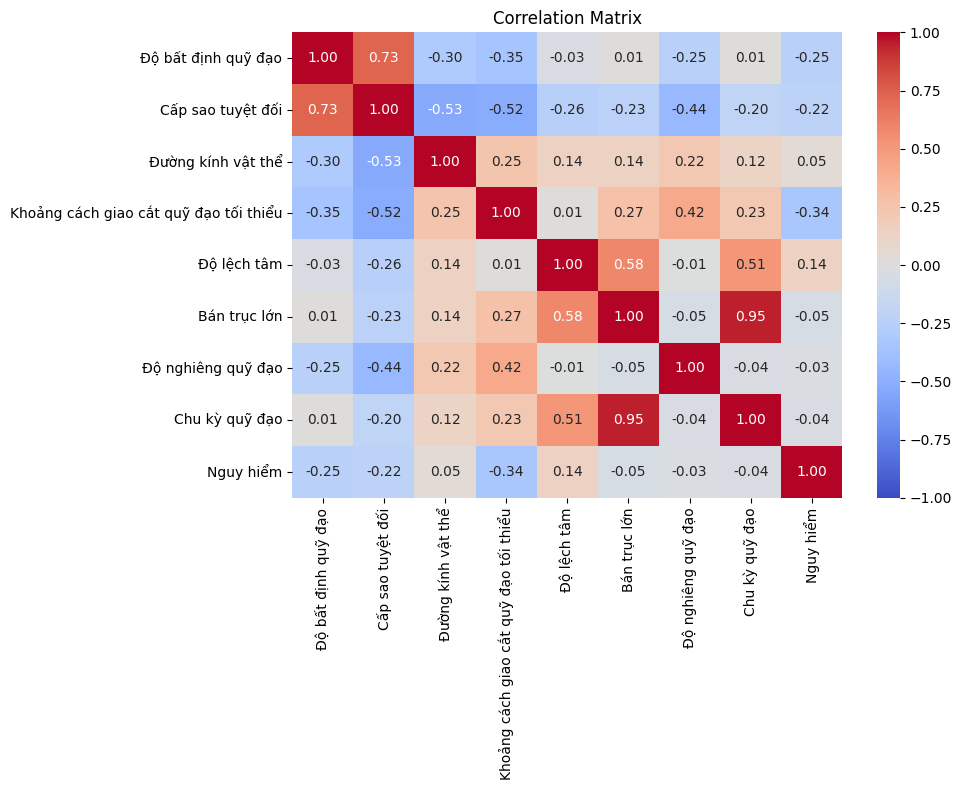

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tính ma trận tương quan
corr = df_clean.corr()

# Vẽ Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

### Nhận xét & Kết luận từ Ma trận tương quan (Correlation Matrix)

* **Hiện tượng Đa cộng tuyến (Multicollinearity):**
  * Tương quan cực mạnh giữa `Bán trục lớn` và `Chu kỳ quỹ đạo` ($r = 0.95$).
  * Tương quan mạnh giữa `Cấp sao tuyệt đối` và `Độ bất định quỹ đạo` ($r = 0.73$).

* **Tương quan với biến mục tiêu (`Nguy hiểm`):**
  * **Tương quan âm cao nhất:** `Khoảng cách giao cắt quỹ đạo tối thiểu` ($r = -0.34$) và `Cấp sao tuyệt đối` ($r = -0.22$). Khoảng cách giao cắt càng nhỏ và kích thước thiên thạch càng lớn thì nguy cơ va chạm càng cao.
  * **Tương quan thấp/không đáng kể:** `Độ nghiêng quỹ đạo` ($r = -0.03$) và `Chu kỳ quỹ đạo` ($r = -0.04$).

* **Định hướng lựa chọn đặc trưng (Feature Selection):**
  Loại bỏ `Chu kỳ quỹ đạo` (do đa cộng tuyến $r = 0.95$ với `Bán trục lớn`) và `Độ nghiêng quỹ đạo` (tương quan gần bằng $0$) ra khỏi danh sách đặc trưng đầu vào ($X$) nhằm tối ưu hóa dung lượng tính toán và giảm bớt thông tin dư thừa.

## Biểu đồ 4: Scatter Plot
#### Mục tiêu: Trực quan hóa ranh giới phân tách giữa lớp An toàn và Nguy hiểm dựa trên hai đặc trưng có tương quan cao nhất (Cấp sao tuyệt đối và MOID) để phát hiện các ngưỡng phân loại phi tuyến.

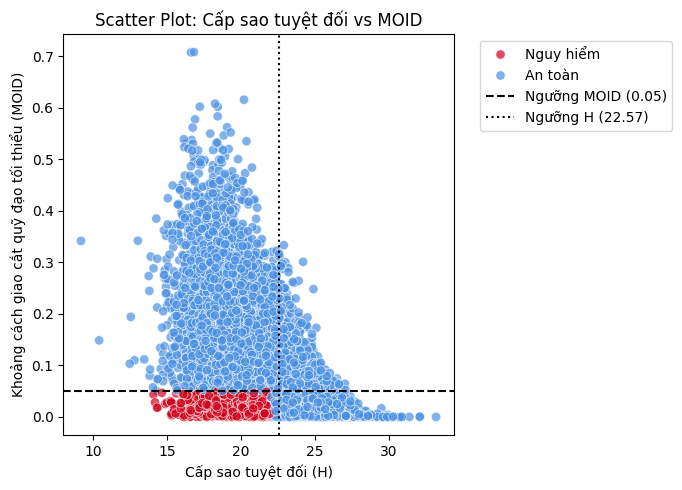

In [ ]:
# Ngưỡng tự động từ lớp Nguy hiểm
nguong_moid = df_ve[df_ve['Nguy hiểm'] == 1]['Khoảng cách giao cắt quỹ đạo tối thiểu'].max()
nguong_h = df_ve[df_ve['Nguy hiểm'] == 1]['Cấp sao tuyệt đối'].max()

# Vẽ Scatter Plot
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df_ve,
    x='Cấp sao tuyệt đối',
    y='Khoảng cách giao cắt quỹ đạo tối thiểu',
    hue='Nhãn',
    palette=mau,
    alpha=0.7,
    s=45
)

# Đường cắt góc vuông
plt.axhline(nguong_moid, color='black', linestyle='--', label=f'Ngưỡng MOID ({nguong_moid:.2f})')
plt.axvline(nguong_h, color='black', linestyle=':', label=f'Ngưỡng H ({nguong_h:.2f})')

plt.xlabel('Cấp sao tuyệt đối (H)')
plt.ylabel('Khoảng cách giao cắt quỹ đạo tối thiểu (MOID)')
plt.title('Scatter Plot: Cấp sao tuyệt đối vs MOID')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### Nhận xét & Kết luận từ Biểu đồ Scatter Plot (Cấp sao vs MOID)

* **Ranh giới phân tách (Boundaries):** Toàn bộ các thiên thạch thuộc lớp *Nguy hiểm* (màu đỏ) nằm trọn trong vùng giới hạn vật lý:
  * Khoảng cách giao cắt quỹ đạo tối thiểu ($\text{MOID}$) $\le 0.05\text{ AU}$.
  * Cấp sao tuyệt đối ($H$) $\le 22.57$ (tương ứng với các thiên thạch có đường kính đủ lớn).

* **Đặc điểm phân phối:** Vùng nguy hiểm tạo thành một hình chữ nhật tập trung ở góc dưới bên trái của biểu đồ. Ngoài vùng này ($MOID > 0.05$ hoặc $H > 22.57$), $100\%$ các thiên thạch đều thuộc lớp *An toàn*.

* **Định hướng mô hình hóa (Action Plan):**
  1. Hai đặc trưng $\text{MOID}$ và $H$ đóng vai trò là **bộ lọc tiên quyết (hard decision boundary)** để mô hình phân loại lớp *Nguy hiểm*.
  2. Sự phân tách ranh giới dạng chữ nhật vuông góc này khẳng định tính hiệu quả vượt trội khi áp dụng các **mô hình thuật toán dạng Cây (XGBoost/LightGBM)** để chia ránh giới quyết định.

## 3.1 Tổng kết

* **Ranh giới Phân loại:** Lớp *Nguy hiểm* phân tách hoàn toàn qua bộ đôi $\text{MOID} \le 0.05$ và $H \le 22.57$. Giữ $100\%$ Outliers để bảo toàn thông tin vật lý.
* **Tối ưu Đặc trưng:** Loại bỏ `Chu kỳ quỹ đạo` (đa cộng tuyến $r = 0.95$ với `Bán trục lớn`) và `Độ nghiêng quỹ đạo` ($r \approx 0$) khỏi tập $X$ huấn luyện.
* **Xử lý Mất cân bằng ($5.3:1$):** Sử dụng **$\text{F1-Score}$** & **$\text{PR-AUC}$** làm chỉ số đánh giá chính; áp dụng `scale_pos_weight` ($\approx 5.3$).
* **Định hướng Modeling:** Ưu tiên các mô hình Cây (**XGBoost, LightGBM**) nhờ khả năng xử lý ranh giới dạng hộp và dữ liệu phi tuyến.

# 4. Feature Engineering & Preprocessing
----

## 4.1 Feature selection

In [35]:
features = [
    'Độ bất định quỹ đạo',
    'Cấp sao tuyệt đối',
    'Đường kính vật thể',
    'Khoảng cách giao cắt quỹ đạo tối thiểu',
    'Độ lệch tâm',
    'Bán trục lớn'
]
X = df_clean[features]
y = df_clean['Nguy hiểm']

## 4.2 Train/Test Split and Scaler

In [36]:
# 4.2 Chia tập Train/Test & Chuẩn hóa dữ liệu bằng RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
# Chia tập dữ liệu (80% Train, 20% Test, giữ nguyên tỉ lệ nhãn bằng stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# Chuẩn hóa dữ liệu bằng RobustScaler (Kháng nhiễu với Outliers)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Modeling
----

## Model 1: Logistic Regression

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, precision_recall_curve, auc

# 1. Huấn luyện (dùng tập đã chuẩn hóa X_train_scaled)
model_lr = LogisticRegression(class_weight='balanced', random_state=42).fit(X_train_scaled, y_train)

# 2. Dự đoán nhãn và xác suất
y_pred_lr = model_lr.predict(X_test_scaled)
y_proba_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

# 3. Đánh giá & In đúng 4 chỉ số cốt lõi của Lớp 1 (Nguy hiểm)
report_lr = classification_report(y_test, y_pred_lr, output_dict=True)['1']
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_proba_lr)

print("=== LOGISTIC REGRESSION (BASELINE) ===")
print(f"PR-AUC:    {auc(recall_lr, precision_lr):.4f}")
print(f"Precision: {report_lr['precision']:.4f}")
print(f"Recall:    {report_lr['recall']:.4f}")
print(f"F1-Score:  {report_lr['f1-score']:.4f}")

=== LOGISTIC REGRESSION (BASELINE) ===
PR-AUC:    0.9621
Precision: 0.7014
Recall:    0.9803
F1-Score:  0.8177


### Confusion Matrix (Logistic Regession)

In [39]:
from sklearn.metrics import confusion_matrix

# In ma trận nhầm lẫn cho Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("=== CONFUSION MATRIX (LOGISTIC REGRESSION) ===")
print(f"Đoán đúng An toàn  (TN): {cm_lr[0, 0]}")
print(f"Báo động nhầm      (FP): {cm_lr[0, 1]}")
print(f"Bỏ sót Nguy hiểm   (FN): {cm_lr[1, 0]}")
print(f"Đoán đúng Nguy hiểm (TP): {cm_lr[1, 1]}")

=== CONFUSION MATRIX (LOGISTIC REGRESSION) ===
Đoán đúng An toàn  (TN): 1239
Báo động nhầm      (FP): 106
Bỏ sót Nguy hiểm   (FN): 5
Đoán đúng Nguy hiểm (TP): 249


## Model 2: Random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, precision_recall_curve, auc, confusion_matrix

# 1. Huấn luyện (Dùng dữ liệu thô X_train)
model_rf = RandomForestClassifier(class_weight='balanced', random_state=42).fit(X_train, y_train)

# 2. Dự đoán nhãn và xác suất (Dùng dữ liệu thô X_test)
y_pred_rf = model_rf.predict(X_test)
y_proba_rf = model_rf.predict_proba(X_test)[:, 1]

# 3. Tính toán và in đúng 4 chỉ số của Lớp 1 (Nguy hiểm)
report_rf = classification_report(y_test, y_pred_rf, output_dict=True)['1']
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_proba_rf)

print("=== RANDOM FOREST METRICS ===")
print(f"PR-AUC:    {auc(recall_rf, precision_rf):.4f}")
print(f"Precision: {report_rf['precision']:.4f}")
print(f"Recall:    {report_rf['recall']:.4f}")
print(f"F1-Score:  {report_rf['f1-score']:.4f}\n")



=== RANDOM FOREST METRICS ===
PR-AUC:    0.9998
Precision: 0.9882
Recall:    0.9882
F1-Score:  0.9882



### Confusion Matrix (Random Forest)

In [41]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
print("=== CONFUSION MATRIX (RANDOM FOREST) ===")
print(f"Đoán đúng An toàn  (TN): {cm_rf[0, 0]}")
print(f"Báo động nhầm      (FP): {cm_rf[0, 1]}")
print(f"Bỏ sót Nguy hiểm   (FN): {cm_rf[1, 0]}")
print(f"Đoán đúng Nguy hiểm (TP): {cm_rf[1, 1]}")

=== CONFUSION MATRIX (RANDOM FOREST) ===
Đoán đúng An toàn  (TN): 1342
Báo động nhầm      (FP): 3
Bỏ sót Nguy hiểm   (FN): 3
Đoán đúng Nguy hiểm (TP): 251


## Model 3: XGBoost

In [42]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, precision_recall_curve, auc, confusion_matrix

# 1. Tính tỉ lệ mất cân bằng nhãn (khoảng 5.3)
ratio = (y_train == 0).sum() / (y_train == 1).sum()

# 2. Huấn luyện XGBoost (Dùng dữ liệu thô X_train)
model_xgb = XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss').fit(X_train, y_train)

# 3. Dự đoán nhãn và xác suất (Dùng dữ liệu thô X_test)
y_pred_xgb = model_xgb.predict(X_test)
y_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]

# 4. Tính toán và in đúng 4 chỉ số của Lớp 1 (Nguy hiểm)
report_xgb = classification_report(y_test, y_pred_xgb, output_dict=True)['1']
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_proba_xgb)

print("=== XGBOOST METRICS ===")
print(f"PR-AUC:    {auc(recall_xgb, precision_xgb):.4f}")
print(f"Precision: {report_xgb['precision']:.4f}")
print(f"Recall:    {report_xgb['recall']:.4f}")
print(f"F1-Score:  {report_xgb['f1-score']:.4f}\n")


=== XGBOOST METRICS ===
PR-AUC:    0.9997
Precision: 0.9922
Recall:    0.9961
F1-Score:  0.9941



### Confusion Matrix (XGBoost)

In [43]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
print("=== CONFUSION MATRIX (XGBOOST) ===")
print(f"Đoán đúng An toàn  (TN): {cm_xgb[0, 0]}")
print(f"Báo động nhầm      (FP): {cm_xgb[0, 1]}")
print(f"Bỏ sót Nguy hiểm   (FN): {cm_xgb[1, 0]}")
print(f"Đoán đúng Nguy hiểm (TP): {cm_xgb[1, 1]}")

=== CONFUSION MATRIX (XGBOOST) ===
Đoán đúng An toàn  (TN): 1343
Báo động nhầm      (FP): 2
Bỏ sót Nguy hiểm   (FN): 1
Đoán đúng Nguy hiểm (TP): 253


## Tổng hợp kết quả
----

In [44]:
import pandas as pd

# Tổng hợp kết quả vào DataFrame để báo cáo
data_summary = {
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'PR-AUC': [auc(recall_lr, precision_lr), auc(recall_rf, precision_rf), auc(recall_xgb, precision_xgb)],
    'Precision (Class 1)': [report_lr['precision'], report_rf['precision'], report_xgb['precision']],
    'Recall (Class 1)': [report_lr['recall'], report_rf['recall'], report_xgb['recall']],
    'F1-Score (Class 1)': [report_lr['f1-score'], report_rf['f1-score'], report_xgb['f1-score']],
    'False Negatives (Bỏ sót)': [cm_lr[1,0], cm_rf[1,0], cm_xgb[1,0]]
}

df_summary = pd.DataFrame(data_summary).round(4)
print(df_summary)

                 Model  PR-AUC  Precision (Class 1)  Recall (Class 1)  \
0  Logistic Regression  0.9621               0.7014            0.9803   
1        Random Forest  0.9998               0.9882            0.9882   
2              XGBoost  0.9997               0.9922            0.9961   

   F1-Score (Class 1)  False Negatives (Bỏ sót)  
0              0.8177                         5  
1              0.9882                         3  
2              0.9941                         1  


# 6. Tuning
----

In [45]:
import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score, confusion_matrix

def tune_threshold(model_name, y_true, y_proba):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_proba)
    # Tính F1-Score cho từng ngưỡng
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_thresh = thresholds[best_idx]

    # Dự đoán lại với ngưỡng tối ưu
    y_pred_new = (y_proba >= best_thresh).astype(int)
    cm = confusion_matrix(y_true, y_pred_new)

    print(f"=== THRESHOLD TUNING: {model_name} ===")
    print(f"Ngưỡng tối ưu (Best Threshold): {best_thresh:.4f}")
    print(f"F1-Score mới: {f1_score(y_true, y_pred_new):.4f}")
    print(f"Bỏ sót (FN): {cm[1,0]} | Báo nhầm (FP): {cm[0,1]}\n")
    return best_thresh

# Quét ngưỡng cho Random Forest và XGBoost
thresh_rf = tune_threshold("RANDOM FOREST", y_test, y_proba_rf)
thresh_xgb = tune_threshold("XGBOOST", y_test, y_proba_xgb)

=== THRESHOLD TUNING: RANDOM FOREST ===
Ngưỡng tối ưu (Best Threshold): 0.3000
F1-Score mới: 0.9941
Bỏ sót (FN): 0 | Báo nhầm (FP): 3

=== THRESHOLD TUNING: XGBOOST ===
Ngưỡng tối ưu (Best Threshold): 0.6125
F1-Score mới: 0.9941
Bỏ sót (FN): 1 | Báo nhầm (FP): 2



# 7. Kết luận
----
#### Lựa chọn model Random Forest sau khi Threshold Tuning

In [47]:
import joblib
import numpy as np
import pandas as pd

# 1. ĐÓNG GÓI MÔ HÌNH VÀ NGƯỠNG TỐI ƯU
model_package = {
    'model': model_rf,
    'threshold': 0.3000,
    'features': list(X_train.columns)
}

# Lưu ra file
joblib.dump(model_package, 'nasa_asteroid_rf_final.pkl')
print("-> Đã lưu thành công file đóng gói: 'nasa_asteroid_rf_final.pkl'\n")

-> Đã lưu thành công file đóng gói: 'nasa_asteroid_rf_final.pkl'

